## 1. Carregar os dados tratados

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix

train = pd.read_parquet("../dados/train_tratado.parquet")
test = pd.read_parquet("../dados/test_tratado.parquet")

X = train.drop(columns="AGE_RANGE")
y = train["AGE_RANGE"]
X_test = test

print("X:", X.shape, "| X_test:", X_test.shape)
print(X.dtypes.map(lambda t: t.name).value_counts())

X: (10962, 287) | X_test: (3655, 287)
category    121
float64     110
int8         54
int64         2
Name: count, dtype: int64


In [ ]:
# Modelo escolhido (hiperparâmetros da procura 2)
modelo_escolhido = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced",
    early_stopping=False, random_state=42, min_samples_leaf=10, max_leaf_nodes=15, max_iter=200,
    max_features=1.0, learning_rate=0.15, l2_regularization=0.5)

## 2. Função de avaliação

Todas as experiências usam **os mesmos 5 folds** (`random_state=42`), para as comparações serem justas.

Para cada modelo guardamos:
- **F1 de validação** (em pessoas que o modelo não viu) → o que interessa;
- **F1 de treino** (nas pessoas com que aprendeu) → se for muito maior do que o de validação, o modelo está a **decorar** (sobreajuste);
- **previsões out-of-fold**: cada pessoa prevista pelo modelo do fold em que ficou de fora (para a matriz de confusão).

`n_jobs=5` treina os 5 folds em paralelo.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def avaliar(modelo, nome):
    inicio = time.time()
    r = cross_validate(modelo, X, y, cv=cv, scoring="f1_macro", return_train_score=True,
                       return_estimator=True, return_indices=True, n_jobs=5)
    oof = np.zeros(len(y), dtype=int)
    for est, idx_val in zip(r["estimator"], r["indices"]["test"]):
        oof[idx_val] = est.predict(X.iloc[idx_val])
    resultado = {
        "modelo": nome,
        "F1 validação": r["test_score"].mean(),
        "desvio": r["test_score"].std(),
        "F1 treino": r["train_score"].mean(),
        "diferença treino-val": r["train_score"].mean() - r["test_score"].mean(),
        "iterações": [e.n_iter_ for e in r["estimator"]],
        "segundos": round(time.time() - inicio),
    }
    print(f"{nome}: validação {resultado['F1 validação']:.4f} ± {resultado['desvio']:.4f} | "
          f"treino {resultado['F1 treino']:.4f} | iterações {resultado['iterações']}")
    return resultado, oof

resultados = [{"modelo": "baseline (dados quase em bruto, 25/10)", "F1 validação": 0.5178, "desvio": 0.0178,
               "F1 treino": 1.0, "diferença treino-val": 0.4822}]

## 3. Parâmetros por defeito nos dados tratados

Mesmo modelo do baseline, só mudam os dados (números convertidos + indicadoras de "Não aplicável").
Assim medimos o efeito **só do tratamento**.

`early_stopping=False` explícito: por defeito (`"auto"`) o early stopping só liga com mais de 10 000 linhas.
Nos folds (≈ 8 770 linhas) ficava desligado, mas no treino final (10 962) ligava-se — o modelo submetido
seria diferente do validado. Assim fica igual nos dois casos.

In [4]:
modelo_defeito = HistGradientBoostingClassifier(
    categorical_features="from_dtype",
    class_weight="balanced",
    early_stopping=False,
    random_state=42,
)
res_defeito, oof_defeito = avaliar(modelo_defeito, "defeito + dados tratados")
resultados.append(res_defeito)

defeito + dados tratados: validação 0.4695 ± 0.0098 | treino 1.0000 | iterações [100, 100, 100, 100, 100]


## 4. Tratar o sobreajuste

**O problema:** no baseline o F1 de treino era **1,000** e o de validação 0,52. O modelo decora o treino.
Além disso, todos os folds pararam nas 100 iterações (o máximo por defeito), ou seja, o *early stopping* nunca atuou.

**Como o boosting sobreajusta:** cada iteração junta árvores que corrigem os erros anteriores. Árvores muito grandes
ou demasiadas iterações acabam a corrigir "erros" que são só ruído de pessoas específicas.

**Hiperparâmetros que regularizam** (tornam o modelo mais simples / mais prudente):

| Hiperparâmetro | O que faz | Efeito no sobreajuste |
|---|---|---|
| `learning_rate` | quanto cada árvore corrige | menor → passos mais pequenos, generaliza melhor (precisa de mais iterações) |
| `max_leaf_nodes` | tamanho máximo de cada árvore | menor → árvores mais simples |
| `min_samples_leaf` | nº mínimo de pessoas numa folha | maior → não cria regras para meia dúzia de pessoas |
| `l2_regularization` | penaliza valores extremos nas folhas | maior → previsões mais suaves |
| `max_features` | fração de colunas que cada divisão pode usar | menor → árvores mais diferentes entre si (como na Random Forest) |
| `early_stopping` | pára quando a perda numa validação interna (10%) deixa de melhorar | evita iterações a mais |

**Procura 1 (regularização forte):** `RandomizedSearchCV` testa 20 combinações aleatórias destes valores (mais barato do que a `GridSearchCV`
do PL 5, que testaria todas). Usa 3 folds para ser mais rápido; o melhor é depois avaliado nos 5 folds de sempre.
Demora vários minutos.

In [5]:
modelo_base = HistGradientBoostingClassifier(
    categorical_features="from_dtype",
    class_weight="balanced",
    max_iter=500,             # limite alto: quem decide quando parar é o early stopping
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
)

grelha = {
    "learning_rate": loguniform(0.02, 0.2),
    "max_leaf_nodes": [7, 15, 31],
    "min_samples_leaf": [20, 50, 100, 200],
    "l2_regularization": [0, 0.1, 1, 5, 10],
    "max_features": [0.2, 0.3, 0.5, 0.8, 1.0],
}

procura = RandomizedSearchCV(
    modelo_base, grelha, n_iter=20, scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    return_train_score=True, random_state=42, n_jobs=-1, verbose=1,
)

inicio = time.time()
procura.fit(X, y)
print(f"Demorou {(time.time() - inicio) / 60:.1f} min")
print("Melhores hiperparâmetros:", procura.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Demorou 15.3 min
Melhores hiperparâmetros: {'l2_regularization': 5, 'learning_rate': np.float64(0.04099596104190036), 'max_features': 0.3, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}


In [6]:
# As 20 combinações, da melhor para a pior
tabela = pd.DataFrame(procura.cv_results_)
tabela = tabela[["param_learning_rate", "param_max_leaf_nodes", "param_min_samples_leaf",
                 "param_l2_regularization", "param_max_features",
                 "mean_train_score", "mean_test_score", "std_test_score"]]
tabela.columns = ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2", "max_features",
                  "F1 treino", "F1 validação", "desvio"]
tabela["diferença"] = tabela["F1 treino"] - tabela["F1 validação"]
tabela.sort_values("F1 validação", ascending=False).round(4)

,learning_rate,max_leaf_nodes,min_samples_leaf,l2,max_features,F1 treino,F1 validação,desvio,diferença
12,0.0410,15,20,5.0,0.3,0.8807,0.4678,0.0073,0.4129
3,0.1054,7,20,0.1,0.3,0.8086,0.4663,0.0081,0.3423
15,0.0489,31,20,10.0,0.3,0.9333,0.4653,0.0062,0.4680
1,0.0286,31,200,0.1,0.5,0.8541,0.4647,0.0092,0.3894
6,0.0482,7,100,1.0,0.8,0.7954,0.4635,0.0037,0.3318
18,0.1184,31,100,0.0,0.8,0.9370,0.4625,0.0026,0.4745
5,0.0818,31,50,1.0,0.3,0.9421,0.4620,0.0063,0.4801
4,0.0818,7,20,5.0,1.0,0.8171,0.4620,0.0055,0.3552
0,0.1785,7,20,5.0,0.5,0.7994,0.4618,0.0060,0.3376
14,0.0792,7,50,5.0,0.8,0.8055,0.4616,0.0050,0.3439


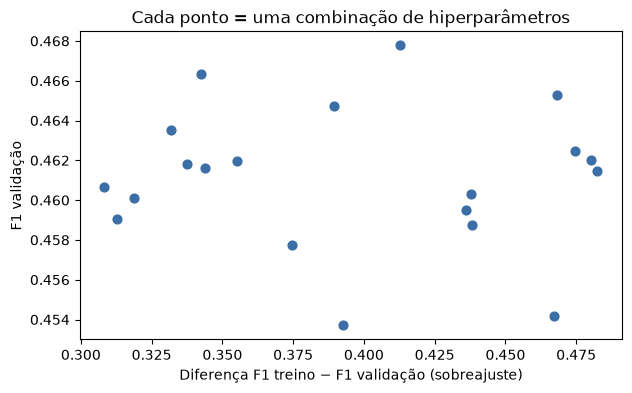

Melhor da procura 1 (3 folds): 0.4678  vs  defeito (5 folds): 0.4695


In [7]:
# Relação entre o sobreajuste (diferença treino-validação) e o F1 de validação
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(tabela["diferença"], tabela["F1 validação"], color="#3b6ea5", s=40)
ax.set_xlabel("Diferença F1 treino − F1 validação (sobreajuste)")
ax.set_ylabel("F1 validação")
ax.set_title("Cada ponto = uma combinação de hiperparâmetros")
plt.show()

print(f"Melhor da procura 1 (3 folds): {procura.best_score_:.4f}  vs  defeito (5 folds): {res_defeito['F1 validação']:.4f}")

### O que a procura 1 mostrou

As combinações com **menos sobreajuste** (diferença treino−validação menor) **não** são as melhores na validação,
e nenhuma bate os parâmetros por defeito (≈ 0,57). Regularizar demasiado (árvores de 7 folhas, early stopping pela
perda) tira capacidade ao modelo: passa a **subajustar**.

**Lição:** no boosting é normal o F1 de treino chegar a 1,0. O critério para escolher é o **F1 de validação**,
não a diferença treino−validação. Regularizar só vale a pena se a validação melhorar.

### Procura 2 — à volta dos parâmetros por defeito

Agora procuramos perto dos valores por defeito (`learning_rate=0.1`, `max_leaf_nodes=31`, `min_samples_leaf=20`, 100 iterações),
com regularização **moderada**, sem early stopping interno (o nº de iterações passa a ser um hiperparâmetro)
e **nos mesmos 5 folds** das outras experiências — o resultado é diretamente comparável. Demora vários minutos.

In [8]:
modelo_base2 = HistGradientBoostingClassifier(
    categorical_features="from_dtype",
    class_weight="balanced",
    early_stopping=False,
    random_state=42,
)

grelha2 = {
    "learning_rate": [0.05, 0.1, 0.15],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 40],
    "l2_regularization": [0, 0.5, 2],
    "max_features": [0.5, 0.7, 1.0],
}

procura2 = RandomizedSearchCV(
    modelo_base2, grelha2, n_iter=15, scoring="f1_macro", cv=cv,
    return_train_score=True, random_state=42, n_jobs=-1, verbose=1,
)

inicio = time.time()
procura2.fit(X, y)
print(f"Demorou {(time.time() - inicio) / 60:.1f} min")
print("Melhores hiperparâmetros:", procura2.best_params_)
print(f"Melhor F1 validação (5 folds): {procura2.best_score_:.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Demorou 147.6 min
Melhores hiperparâmetros: {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_features': 0.5, 'learning_rate': 0.1, 'l2_regularization': 0.5}
Melhor F1 validação (5 folds): 0.4750


In [9]:
tabela2 = pd.DataFrame(procura2.cv_results_)
colunas = ["param_" + p for p in grelha2] + ["mean_train_score", "mean_test_score", "std_test_score"]
tabela2 = tabela2[colunas].rename(columns=lambda c: c.replace("param_", ""))
tabela2 = tabela2.rename(columns={"mean_train_score": "F1 treino", "mean_test_score": "F1 validação", "std_test_score": "desvio"})
tabela2.sort_values("F1 validação", ascending=False).round(4)

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,F1 treino,F1 validação,desvio
9,0.10,300,15,10,0.5,0.5,1.0000,0.4750,0.0066
6,0.05,300,15,10,0.0,1.0,0.9988,0.4740,0.0054
4,0.05,100,15,40,2.0,0.7,0.8831,0.4733,0.0051
7,0.10,100,15,10,0.0,0.5,0.9871,0.4704,0.0125
0,0.15,200,15,10,0.5,1.0,1.0000,0.4697,0.0067
1,0.10,200,31,20,0.0,1.0,1.0000,0.4676,0.0077
13,0.15,100,15,20,0.5,0.7,0.9967,0.4658,0.0087
3,0.10,100,31,20,0.5,0.7,1.0000,0.4658,0.0069
11,0.15,100,63,20,2.0,1.0,1.0000,0.4657,0.0064
8,0.10,300,63,20,0.0,0.7,1.0000,0.4654,0.0090


In [10]:
# Escolher o modelo com melhor F1 de validação (mesmos 5 folds): defeito ou melhor da procura 2
if procura2.best_score_ > res_defeito["F1 validação"]:
    modelo_escolhido, nome_escolhido = procura2.best_estimator_, "procura 2 + dados tratados"
else:
    modelo_escolhido, nome_escolhido = modelo_defeito, "defeito + dados tratados"
print("Escolhido:", nome_escolhido)

Escolhido: procura 2 + dados tratados


## 5. Avaliar o modelo escolhido

Todos os modelos na tabela foram avaliados nos **mesmos 5 folds**, por isso comparam-se diretamente.

In [11]:
# Procura 1: o melhor reavaliado nos mesmos 5 folds, para ficar na tabela
res_p1, _ = avaliar(procura.best_estimator_, "procura 1 (regularização forte)")
resultados.append(res_p1)

if nome_escolhido == "defeito + dados tratados":
    oof_escolhido = oof_defeito
else:
    res, oof_escolhido = avaliar(modelo_escolhido, nome_escolhido)
    resultados.append(res)

pd.DataFrame(resultados).set_index("modelo").round(4)

procura 1 (regularização forte): validação 0.4674 ± 0.0046 | treino 0.8638 | iterações [170, 132, 196, 153, 151]


procura 2 + dados tratados: validação 0.4750 ± 0.0066 | treino 1.0000 | iterações [300, 300, 300, 300, 300]


,F1 validação,desvio,F1 treino,diferença treino-val,iterações,segundos
modelo,,,,,,
"baseline (dados quase em bruto, 25/10)",0.5178,0.0178,1.0000,0.4822,NaN,NaN
defeito + dados tratados,0.4695,0.0098,1.0000,0.5304,"[100, 100, 100, 100, 100]",104.0
procura 1 (regularização forte),0.4674,0.0046,0.8638,0.3964,"[170, 132, 196, 153, 151]",212.0
procura 2 + dados tratados,0.4750,0.0066,1.0000,0.5250,"[300, 300, 300, 300, 300]",331.0


## 6. Onde o modelo erra

- **Relatório por faixa:** precision, recall e F1 de cada faixa (o Macro F1 é a média da coluna `f1-score`).
- **Matriz de confusão:** linhas = faixa real, colunas = faixa prevista; normalizada por linha (cada linha soma 100%).

In [12]:
print(classification_report(y, oof_escolhido, digits=3))

              precision    recall  f1-score   support

           0      0.809     0.918     0.860       207
           1      0.441     0.302     0.359       172
           2      0.593     0.634     0.613       399
           3      0.435     0.382     0.407       377
           4      0.312     0.274     0.292       449
           5      0.352     0.360     0.356       647
           6      0.348     0.364     0.356       859
           7      0.400     0.398     0.399       862
           8      0.623     0.657     0.640       905
           9      0.648     0.687     0.667      1014
          10      0.621     0.652     0.636      1062
          11      0.552     0.525     0.538      1040
          12      0.360     0.389     0.374      1000
          13      0.293     0.278     0.285       823
          14      0.356     0.328     0.341       650
          15      0.513     0.462     0.486       496

    accuracy                          0.478     10962
   macro avg      0.479   

In [13]:
# F1 por faixa: parâmetros por defeito vs modelo escolhido
from sklearn.metrics import f1_score
comparacao = pd.DataFrame({
    "defeito": f1_score(y, oof_defeito, average=None),
    "escolhido": f1_score(y, oof_escolhido, average=None),
}).round(3)
comparacao["diferença"] = comparacao["escolhido"] - comparacao["defeito"]
comparacao.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
defeito,0.846,0.303,0.610,0.381,0.298,0.374,0.362,0.403,0.638,0.662,0.642,0.522,0.391,0.292,0.341,0.460
escolhido,0.860,0.359,0.613,0.407,0.292,0.356,0.356,0.399,0.640,0.667,0.636,0.538,0.374,0.285,0.341,0.486
diferença,0.014,0.056,0.003,0.026,-0.006,-0.018,-0.006,-0.004,0.002,0.005,-0.006,0.016,-0.017,-0.007,0.000,0.026


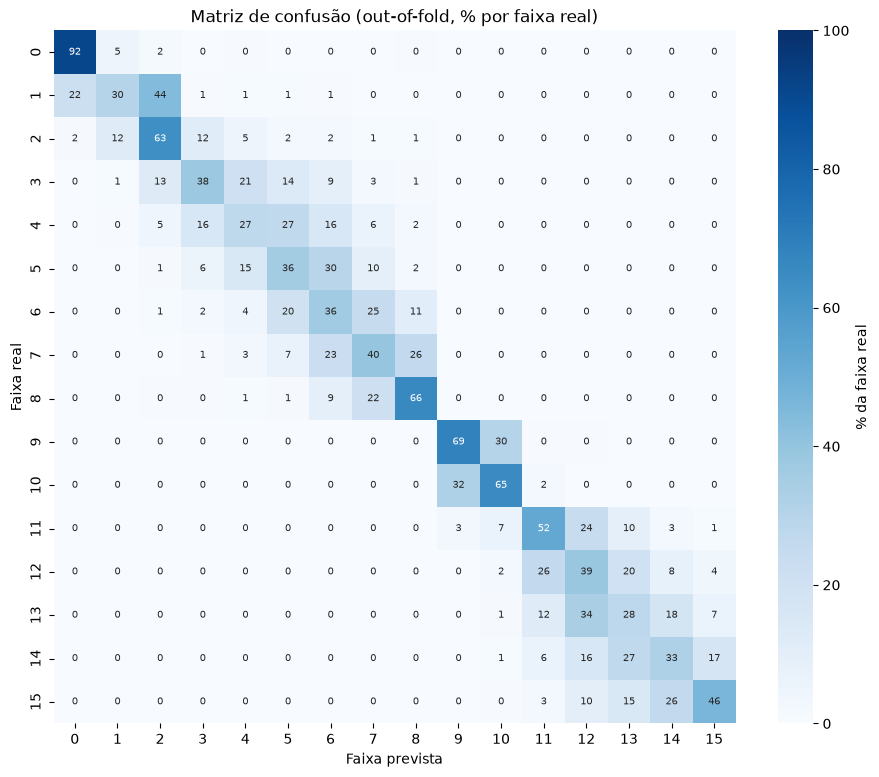

In [14]:
matriz = confusion_matrix(y, oof_escolhido, normalize="true") * 100

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz, cmap="Blues", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% da faixa real"}, ax=ax)
ax.set_xlabel("Faixa prevista")
ax.set_ylabel("Faixa real")
ax.set_title("Matriz de confusão (out-of-fold, % por faixa real)")
plt.show()

In [15]:
# Quão longe ficam os erros? (0 = acerto, 1 = faixa vizinha, ...)
distancia = np.abs(oof_escolhido - y.values)
print((pd.Series(distancia).value_counts(normalize=True).sort_index() * 100).round(1).head(8))

0    47.8
1    37.6
2    10.3
3     3.1
4     0.8
5     0.2
6     0.1
8     0.0
Name: proportion, dtype: float64


## 7. Treinar com o treino todo e gerar a submissão

O modelo final é treinado com **todas** as linhas do treino, com os hiperparâmetros escolhidos.
Formato do Kaggle: `RowId,AGE_RANGE`, com `RowId` = ordem das linhas do teste (0 a 3654).

In [16]:
modelo_final = HistGradientBoostingClassifier(**modelo_escolhido.get_params())
modelo_final.fit(X, y)
print("Iterações usadas:", modelo_final.n_iter_)

submissao = pd.DataFrame({
    "RowId": np.arange(len(X_test)),
    "AGE_RANGE": modelo_final.predict(X_test),
})

os.makedirs("../submissions", exist_ok=True)
caminho = "../submissions/hgb_tratado.csv"
submissao.to_csv(caminho, index=False)
print("Guardado em", caminho, "|", submissao.shape)

Iterações usadas: 300


Guardado em ../submissions/hgb_tratado.csv | (3655, 2)


In [17]:
# Verificações antes de submeter
exemplo = pd.read_csv("../dados/example_submission_10.csv")
assert list(submissao.columns) == list(exemplo.columns), "colunas diferentes do exemplo"
assert len(submissao) == len(exemplo), "nº de linhas diferente do exemplo"
assert (submissao["RowId"] == exemplo["RowId"]).all(), "RowId diferente do exemplo"
assert submissao["AGE_RANGE"].between(0, 15).all(), "faixas fora de 0-15"

pd.DataFrame({
    "treino %": y.value_counts(normalize=True).sort_index() * 100,
    "previsto teste %": submissao["AGE_RANGE"].value_counts(normalize=True).sort_index() * 100,
}).round(1).T

AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
treino %,1.9,1.6,3.6,3.4,4.1,5.9,7.8,7.9,8.3,9.3,9.7,9.5,9.1,7.5,5.9,4.5
previsto teste %,1.9,1.1,3.6,3.3,3.7,6.1,7.9,8.6,8.3,9.4,10.5,9.4,9.8,7.4,5.0,4.0


## Registo

Para o `experiencias.md` (preencher com os valores da tabela da secção 5):

| Data | Experiência | F1 validação | F1 Kaggle | Notas |
|---|---|---|---|---|
| 25/10 | HGB baseline, dados quase em bruto | 0,518 ± 0,018 | | treino 1,000 → sobreajuste |
| _(data)_ | HGB defeito + números convertidos + indicadoras NA | | | |
| _(data)_ | HGB procura 1 (regularização forte) | | | pior: subajusta |
| _(data)_ | HGB escolhido (defeito ou procura 2) | | | `hgb_tratado.csv` |

## 8. Gráficos de sobreajuste

Dois gráficos clássicos para diagnosticar sobreajuste:

**a) Curva por iteração** — o modelo é treinado com mais iterações do que o escolhido e, a cada iteração,
medimos o desempenho no treino e na validação (`staged_predict`: previsões do modelo "parcial" após 1, 2, ... iterações).
- Treino a subir sempre e validação a estabilizar → a partir daí as iterações extra só decoram o treino.
- Log loss de validação a **subir** enquanto a de treino desce → sobreajuste clássico.
- A linha vertical marca o nº de iterações escolhido.

**b) Curva de aprendizagem** — o modelo é treinado com 20%, 40%, ..., 100% dos dados de treino de cada fold.
- **Diferença grande** entre treino e validação → variância alta (sobreajuste): ajudam regularização, menos colunas, ensembles.
- **Validação ainda a subir** no fim → mais dados ajudariam (aqui não há mais, mas mostra que o modelo está limitado pelos dados).
- **As duas curvas baixas e juntas** → subajuste: o modelo é demasiado simples ou faltam features.

Cada curva mostra a média dos 5 folds (linha) e ± 1 desvio padrão (sombra). Demora alguns minutos.

### a) Curva por iteração

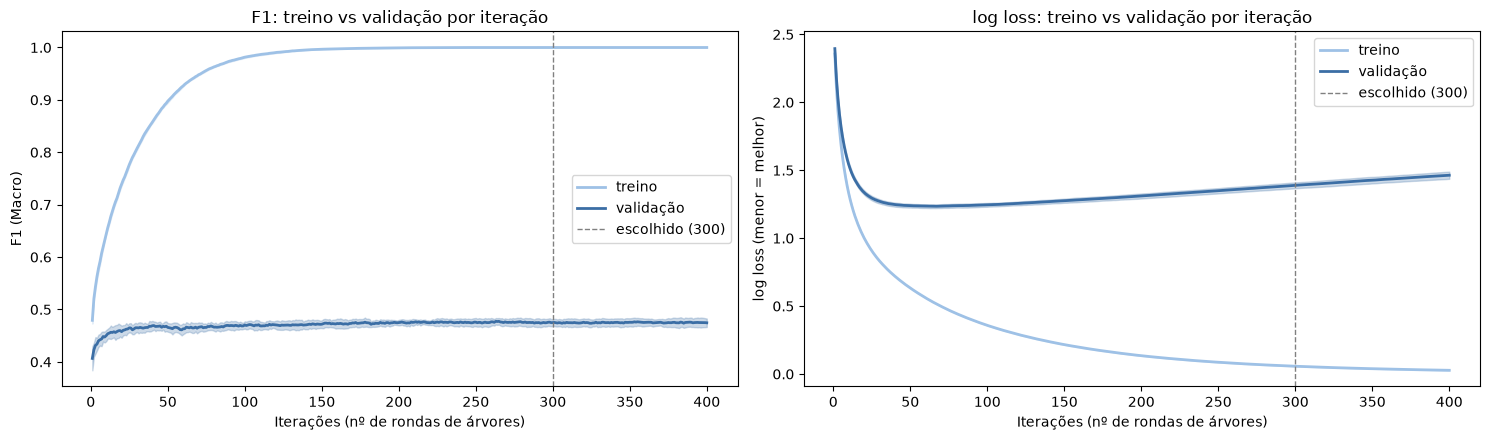

F1 validação: máximo 0.4774 na iteração 263 | na iteração escolhida 0.4750
Log loss validação: mínimo 1.2347 na iteração 66 | na iteração escolhida 1.3888


In [18]:
from joblib import Parallel, delayed
from sklearn.metrics import f1_score, log_loss

MAX_ITER_CURVA = 400
params_curva = {**modelo_escolhido.get_params(), "max_iter": MAX_ITER_CURVA}

def curva_fold(i_tr, i_val):
    m = HistGradientBoostingClassifier(**params_curva).fit(X.iloc[i_tr], y.iloc[i_tr])
    out = {}
    for nome, idx in [("treino", i_tr), ("validação", i_val)]:
        yy = y.iloc[idx]
        out[f"F1 {nome}"] = [f1_score(yy, p, average="macro") for p in m.staged_predict(X.iloc[idx])]
        out[f"log loss {nome}"] = [log_loss(yy, p, labels=m.classes_) for p in m.staged_predict_proba(X.iloc[idx])]
    return out

folds = Parallel(n_jobs=5)(delayed(curva_fold)(i_tr, i_val) for i_tr, i_val in cv.split(X, y))
curvas = {k: np.array([f[k] for f in folds]) for k in folds[0]}
iteracoes = np.arange(1, MAX_ITER_CURVA + 1)
n_escolhido = modelo_escolhido.get_params()["max_iter"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metrica in zip(axes, ["F1", "log loss"]):
    for nome, cor in [("treino", "#9ec1e6"), ("validação", "#3b6ea5")]:
        v = curvas[f"{metrica} {nome}"]
        ax.plot(iteracoes, v.mean(0), color=cor, lw=2, label=nome)
        ax.fill_between(iteracoes, v.mean(0) - v.std(0), v.mean(0) + v.std(0), color=cor, alpha=0.25)
    ax.axvline(n_escolhido, color="grey", ls="--", lw=1, label=f"escolhido ({n_escolhido})")
    ax.set_xlabel("Iterações (nº de rondas de árvores)")
    ax.set_ylabel(metrica + (" (Macro)" if metrica == "F1" else " (menor = melhor)"))
    ax.set_title(f"{metrica}: treino vs validação por iteração")
    ax.legend()
plt.tight_layout()
plt.show()

v_f1 = curvas["F1 validação"].mean(0)
v_ll = curvas["log loss validação"].mean(0)
print(f"F1 validação: máximo {v_f1.max():.4f} na iteração {v_f1.argmax() + 1} | na iteração escolhida {v_f1[n_escolhido - 1]:.4f}")
print(f"Log loss validação: mínimo {v_ll.min():.4f} na iteração {v_ll.argmin() + 1} | na iteração escolhida {v_ll[n_escolhido - 1]:.4f}")

### b) Curva de aprendizagem

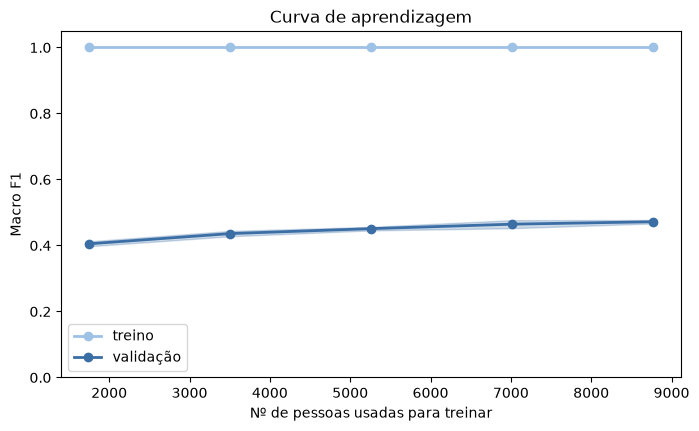

,pessoas no treino,F1 treino,F1 validação,diferença
0,1753,1.0,0.4052,0.5948
1,3507,1.0,0.4361,0.5639
2,5261,1.0,0.4511,0.5489
3,7015,1.0,0.4646,0.5354
4,8769,1.0,0.4720,0.5280


In [19]:
from sklearn.model_selection import learning_curve

fracoes = [0.2, 0.4, 0.6, 0.8, 1.0]
tamanhos, f1_tr, f1_val = learning_curve(
    modelo_escolhido, X, y, cv=cv, train_sizes=fracoes, scoring="f1_macro",
    n_jobs=-1, shuffle=True, random_state=42,
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for valores, nome, cor in [(f1_tr, "treino", "#9ec1e6"), (f1_val, "validação", "#3b6ea5")]:
    ax.plot(tamanhos, valores.mean(1), "o-", color=cor, lw=2, label=nome)
    ax.fill_between(tamanhos, valores.mean(1) - valores.std(1), valores.mean(1) + valores.std(1), color=cor, alpha=0.25)
ax.set_xlabel("Nº de pessoas usadas para treinar")
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 1.05)
ax.set_title("Curva de aprendizagem")
ax.legend()
plt.show()

pd.DataFrame({"pessoas no treino": tamanhos, "F1 treino": f1_tr.mean(1), "F1 validação": f1_val.mean(1),
              "diferença": f1_tr.mean(1) - f1_val.mean(1)}).round(4)

## 9. Preparar para o ensemble (stacking)

Grava as **probabilidades** das 16 faixas (não só a faixa prevista): no stacking, o modelo final precisa de saber
**quão confiante** o HGB está (ex: 45% faixa 7 e 40% faixa 8 é muito diferente de 90% faixa 7).

- **Treino:** probabilidades *out-of-fold* — cada pessoa prevista pelo modelo do fold em que ficou de fora
  (nunca pelo modelo que a viu no treino). Mesmos 5 folds do Random Forest e do regressor (`random_state=42`).
- **Teste:** probabilidades do modelo treinado com todos os dados de treino.

Secção **independente** (carrega os dados e define o modelo de novo), com os hiperparâmetros da procura 2,
avaliados nos dados tratados atuais (com as escalas ordinais mapeadas): Macro F1 0,5891.

In [20]:
import os
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

train = pd.read_parquet("../dados/train_tratado.parquet")
test = pd.read_parquet("../dados/test_tratado.parquet")
X = train.drop(columns="AGE_RANGE")
y = train["AGE_RANGE"]
X_test = test[X.columns]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

PARAMS_PROCURA_2 = {"learning_rate": 0.15, "max_iter": 200, "max_leaf_nodes": 15, "min_samples_leaf": 10,
                    "max_features": 1.0, "l2_regularization": 0.5}

def criar_hgb():
    return HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced",
                                          early_stopping=False, random_state=42, **PARAMS_PROCURA_2)

oof_proba = cross_val_predict(criar_hgb(), X, y, cv=cv, method="predict_proba", n_jobs=5)

# Verificação: deve dar o mesmo F1 da procura 2 nos dados atuais (0,5891)
f1_folds = [f1_score(y.iloc[b], oof_proba[b].argmax(1), average="macro") for _, b in cv.split(X, y)]
print(f"OOF: Macro F1 {np.mean(f1_folds):.4f} ± {np.std(f1_folds):.4f}")

OOF: Macro F1 0.4697 ± 0.0067


In [21]:
final = criar_hgb().fit(X, y)
test_proba = final.predict_proba(X_test)

os.makedirs("../resultados", exist_ok=True)      # previsões ligadas aos dados: não vão para o GitHub
colunas = [f"p_{k}" for k in range(16)]
pid = pd.read_csv("../dados/dataset_train.csv", usecols=["PID"])["PID"].values
oof_df = pd.DataFrame(oof_proba, columns=colunas)
oof_df.insert(0, "PID", pid)
oof_df["real"] = y.values
oof_df.to_csv("../resultados/oof_hgb.csv", index=False)
pd.DataFrame(test_proba, columns=colunas).to_csv("../resultados/test_proba_hgb.csv", index=False)

assert len(test_proba) == 3655
print("Gravados: ../resultados/oof_hgb.csv e ../resultados/test_proba_hgb.csv")

Gravados: ../resultados/oof_hgb.csv e ../resultados/test_proba_hgb.csv
